In [2]:
# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Saving the model
import joblib

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Dataset URL
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

# Read the dataset
df = pd.read_csv(url)

# Display the first five rows
print("Titanic Dataset:")
display(df.head())

# Display the number of rows and columns
print("Dataset Shape:", df.shape)

Titanic Dataset:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Dataset Shape: (891, 12)


In [4]:
# Dataset information
print("Dataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Statistical Summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Duplicate Rows: 0


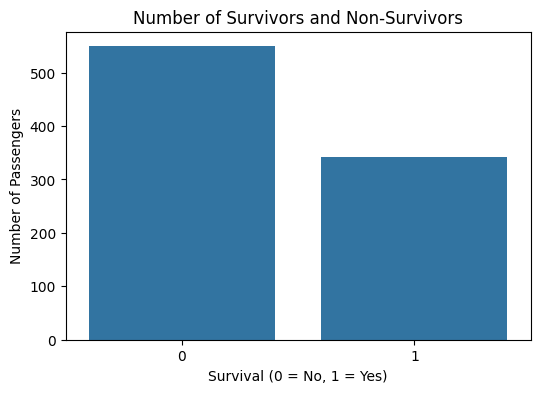

In [5]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Survived")

plt.title("Number of Survivors and Non-Survivors")
plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

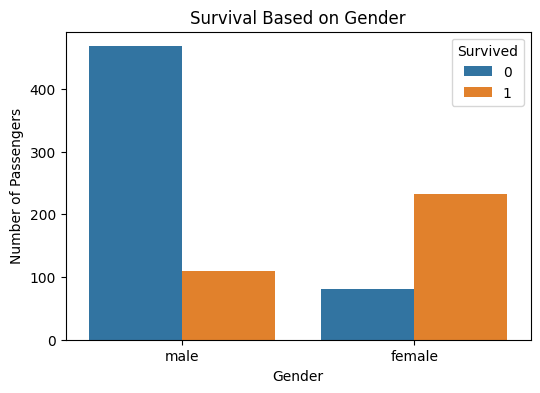

In [6]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Sex", hue="Survived")

plt.title("Survival Based on Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

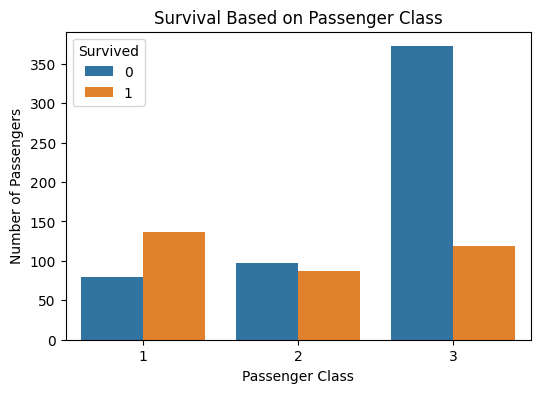

In [7]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Pclass", hue="Survived")

plt.title("Survival Based on Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()

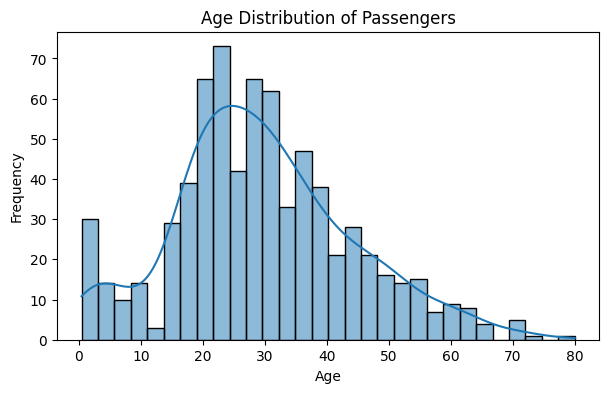

In [8]:
plt.figure(figsize=(7, 4))

sns.histplot(data=df, x="Age", bins=30, kde=True)

plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

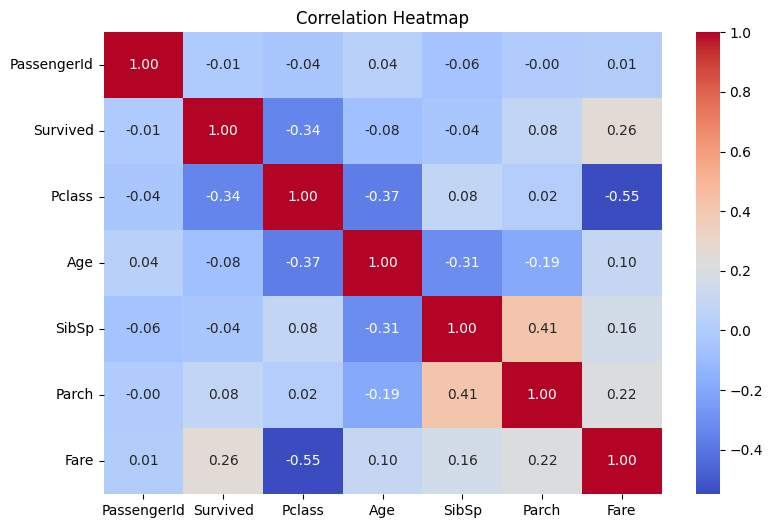

In [9]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [10]:
# Create a copy of the dataset
data = df.copy()

# Create new features
data["FamilySize"] = data["SibSp"] + data["Parch"] + 1

data["IsAlone"] = (data["FamilySize"] == 1).astype(int)

# Select input features
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked",
    "FamilySize",
    "IsAlone"
]

X = data[features]

# Select target
y = data["Survived"]

print("Input Features:")
display(X.head())

print("\nTarget Values:")
print(y.head())

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features:


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone
0,3,male,22.0,1,0,7.2500,S,2,0
1,1,female,38.0,1,0,71.2833,C,2,0
2,3,female,26.0,0,0,7.9250,S,1,1
3,1,female,35.0,1,0,53.1000,S,2,0
4,3,male,35.0,0,0,8.0500,S,1,1



Target Values:
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

Feature Shape: (891, 9)
Target Shape: (891,)


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (712, 9)
Testing Features: (179, 9)
Training Target: (712,)
Testing Target: (179,)


In [12]:
# Numerical columns
numerical_features = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize",
    "IsAlone"
]

# Categorical columns
categorical_features = [
    "Sex",
    "Embarked"
]

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [13]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),

    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Random Forest": RandomForestClassifier(random_state=42),

    "Support Vector Machine": SVC(probability=True, random_state=42)
}

print("Four Machine Learning models created successfully!")

Four Machine Learning models created successfully!


In [14]:
param_grids = {

    "Logistic Regression": {
        "model__C": [0.1, 1, 10],
        "model__solver": ["liblinear"]
    },

    "Decision Tree": {
        "model__max_depth": [3, 5, 10, None],
        "model__min_samples_split": [2, 5]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [5, 10, None],
        "model__min_samples_split": [2, 5]
    },

    "Support Vector Machine": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"]
    }
}

print("Hyperparameter grids defined successfully!")

Hyperparameter grids defined successfully!


In [15]:
# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Store results
best_models = {}
cv_results = []

# Train and tune all four models
for name, model in models.items():

    print("\nTraining:", name)

    # Create complete pipeline
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # GridSearchCV
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring=scoring,
        refit="f1",
        cv=cv,
        n_jobs=-1,
        verbose=1
    )

    # Train the model
    grid_search.fit(X_train, y_train)

    # Save the best model
    best_models[name] = grid_search.best_estimator_

    # Save cross-validation results
    cv_results.append({
        "Model": name,
        "Best CV Precision": grid_search.cv_results_["mean_test_precision"][
            grid_search.best_index_
        ],
        "Best CV Recall": grid_search.cv_results_["mean_test_recall"][
            grid_search.best_index_
        ],
        "Best CV F1": grid_search.best_score_,
        "Best CV ROC-AUC": grid_search.cv_results_["mean_test_roc_auc"][
            grid_search.best_index_
        ],
        "Best Parameters": grid_search.best_params_
    })

    print("Best Parameters:", grid_search.best_params_)
    print("Best Cross-Validation F1:", round(grid_search.best_score_, 4))

print("\nAll four models trained and tuned successfully!")


Training: Logistic Regression
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best Parameters: {'model__C': 1, 'model__solver': 'liblinear'}
Best Cross-Validation F1: 0.7294

Training: Decision Tree
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Parameters: {'model__max_depth': 10, 'model__min_samples_split': 5}
Best Cross-Validation F1: 0.7261

Training: Random Forest
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters: {'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 100}
Best Cross-Validation F1: 0.7508

Training: Support Vector Machine
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best Parameters: {'model__C': 1, 'model__kernel': 'rbf'}
Best Cross-Validation F1: 0.7559

All four models trained and tuned successfully!


In [16]:
cv_comparison = pd.DataFrame(cv_results)

cv_comparison = cv_comparison.sort_values(
    by="Best CV F1",
    ascending=False
)

print("Cross-Validation Model Comparison:")
display(cv_comparison)

Cross-Validation Model Comparison:


,Model,Best CV Precision,Best CV Recall,Best CV F1,Best CV ROC-AUC,Best Parameters
3,Support Vector Machine,0.805081,0.714276,0.755885,0.847826,"{'model__C': 1, 'model__kernel': 'rbf'}"
2,Random Forest,0.795912,0.714209,0.750763,0.872809,"{'model__max_depth': 10, 'model__min_samples_s..."
0,Logistic Regression,0.756584,0.707205,0.729435,0.856010,"{'model__C': 1, 'model__solver': 'liblinear'}"
1,Decision Tree,0.773164,0.684983,0.726125,0.805029,"{'model__max_depth': 10, 'model__min_samples_s..."


In [17]:
test_results = []

for name, model in best_models.items():

    # Predict survival
    y_pred = model.predict(X_test)

    # Predict survival probabilities
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)

    test_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    })

    print("\nModel:", name)
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))
    print("ROC-AUC:", round(roc_auc, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))


Model: Logistic Regression
Accuracy: 0.8045
Precision: 0.7833
Recall: 0.6812
F1 Score: 0.7287
ROC-AUC: 0.8506

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.88      0.85       110
           1       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179


Model: Decision Tree
Accuracy: 0.7765
Precision: 0.7458
Recall: 0.6377
F1 Score: 0.6875
ROC-AUC: 0.7503

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.86      0.83       110
           1       0.75      0.64      0.69        69

    accuracy                           0.78       179
   macro avg       0.77      0.75      0.76       179
weighted avg       0.77      0.78      0.77       179


Model: Random Forest
Accuracy: 0.8045
Precision: 0.7931
Recall: 0.6667
F1 Score: 

In [18]:
test_comparison = pd.DataFrame(test_results)

test_comparison = test_comparison.sort_values(
    by="F1 Score",
    ascending=False
)

print("Final Test Performance Comparison:")
display(test_comparison)

Final Test Performance Comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,Support Vector Machine,0.821229,0.824561,0.681159,0.746032,0.839657
0,Logistic Regression,0.804469,0.783333,0.681159,0.728682,0.850593
2,Random Forest,0.804469,0.793103,0.666667,0.724409,0.832740
1,Decision Tree,0.776536,0.745763,0.637681,0.687500,0.750264


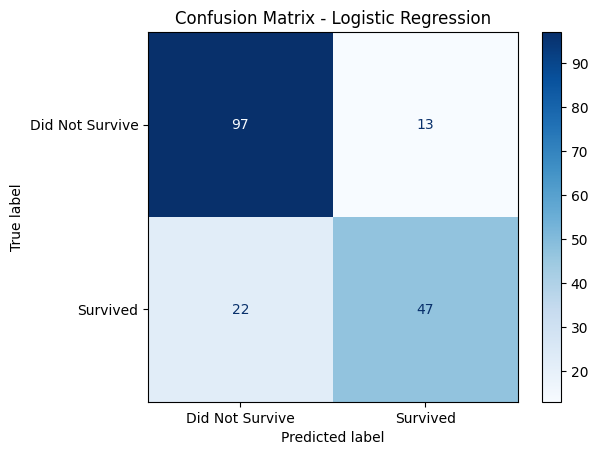

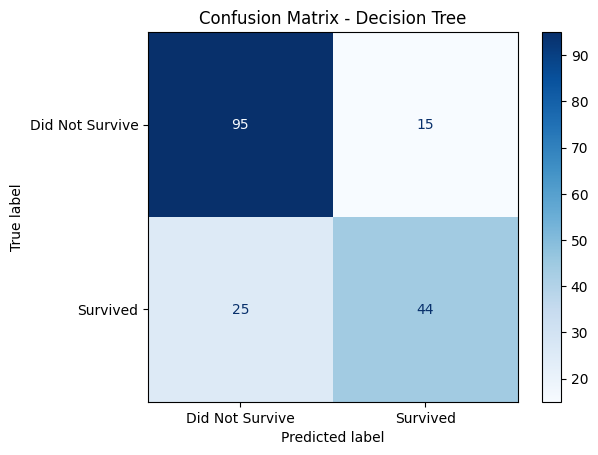

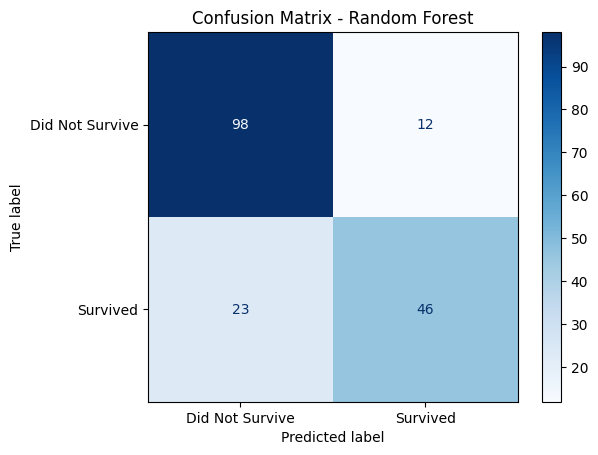

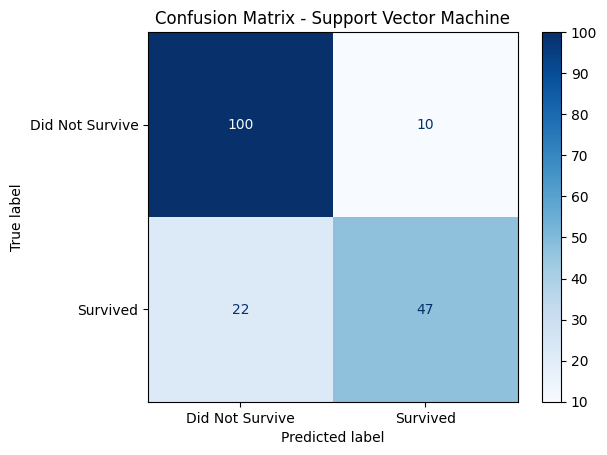

In [19]:
for name, model in best_models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Did Not Survive", "Survived"]
    )

    disp.plot(cmap="Blues")

    plt.title("Confusion Matrix - " + name)
    plt.show()

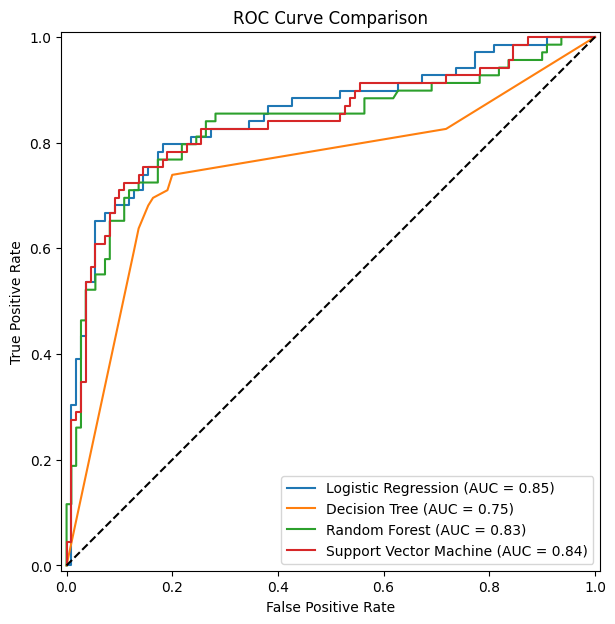

In [20]:
plt.figure(figsize=(9, 7))

for name, model in best_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=name,
        ax=plt.gca()
    )

plt.plot([0, 1], [0, 1], "k--")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.show()

In [21]:
champion_name = cv_comparison.iloc[0]["Model"]

champion_model = best_models[champion_name]

print("CHAMPION MODEL:", champion_name)

print(
    "Cross-Validation F1 Score:",
    round(cv_comparison.iloc[0]["Best CV F1"], 4)
)

print("\nChampion Model Test Results:")

display(
    test_comparison[
        test_comparison["Model"] == champion_name
    ]
)

CHAMPION MODEL: Support Vector Machine
Cross-Validation F1 Score: 0.7559

Champion Model Test Results:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,Support Vector Machine,0.821229,0.824561,0.681159,0.746032,0.839657


In [22]:
# Save the complete model pipeline
joblib.dump(
    champion_model,
    "titanic_champion_model.joblib"
)

print("Champion model saved successfully!")

Champion model saved successfully!


In [23]:
# Load the saved model
loaded_model = joblib.load("titanic_champion_model.joblib")

# Make predictions using the loaded model
loaded_predictions = loaded_model.predict(X_test)

# Check the accuracy
loaded_accuracy = accuracy_score(y_test, loaded_predictions)

print("Loaded Model Accuracy:", round(loaded_accuracy, 4))

print("Model loaded and tested successfully!")

Loaded Model Accuracy: 0.8212
Model loaded and tested successfully!


In [24]:
# Save cross-validation results
cv_comparison.to_csv(
    "titanic_cv_comparison.csv",
    index=False
)

# Save test results
test_comparison.to_csv(
    "titanic_test_comparison.csv",
    index=False
)

print("Comparison files saved successfully!")

Comparison files saved successfully!


In [25]:
from google.colab import files

# Download trained model
files.download("titanic_champion_model.joblib")

# Download cross-validation comparison
files.download("titanic_cv_comparison.csv")

# Download test comparison
files.download("titanic_test_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>